<a href="https://colab.research.google.com/github/rjlobosco/unifesp/blob/main/Tarefa_Interpolacao_Erros.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.


## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**



### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

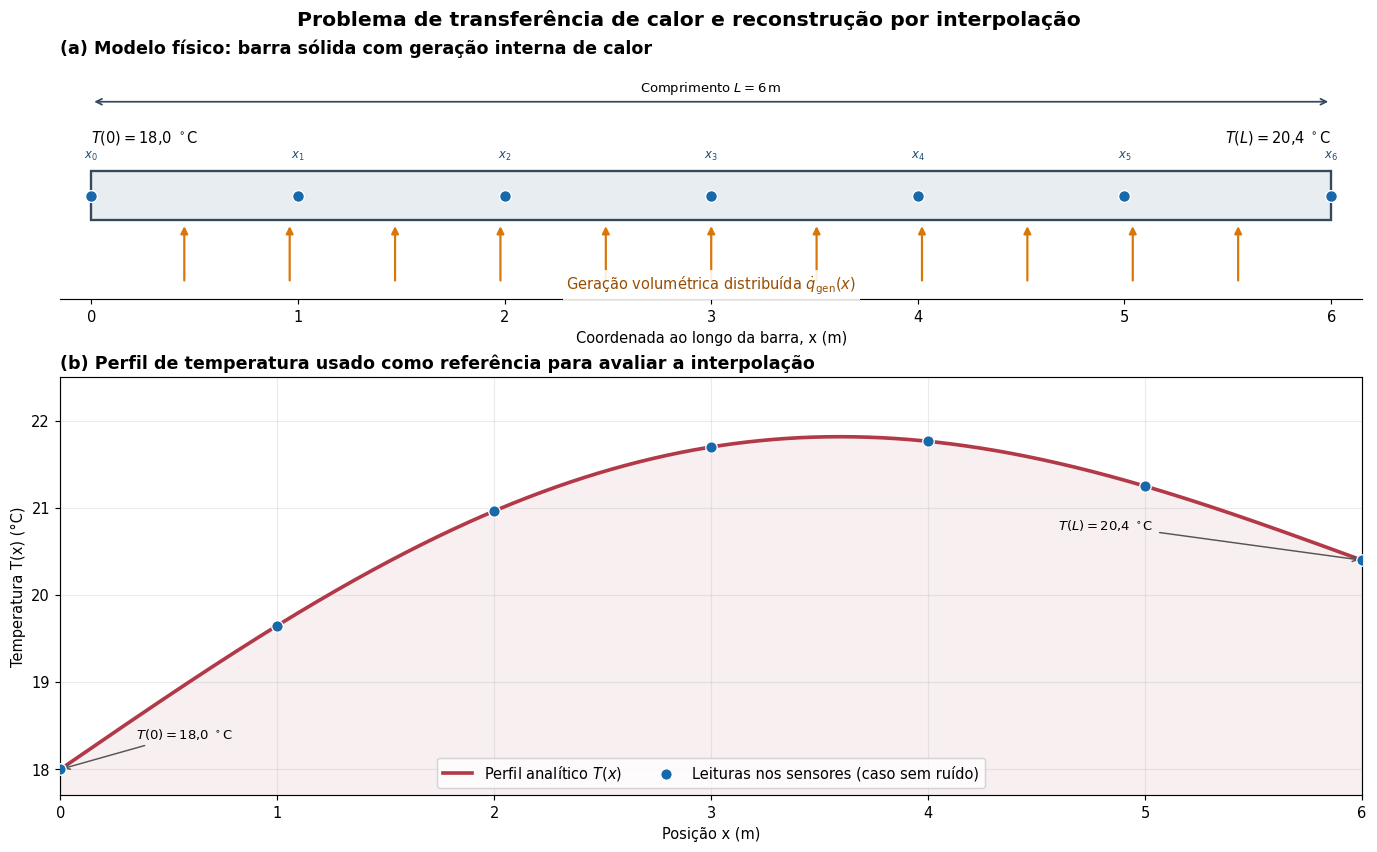

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [1]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

Spline quadrática

In [2]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,0.000085,0.000019,0.000033
1,Spline cúbica natural,0.000506,0.000184,0.000239
2,Spline quadrática,0.023927,0.014950,0.016466
3,Spline linear,0.082294,0.036510,0.043967


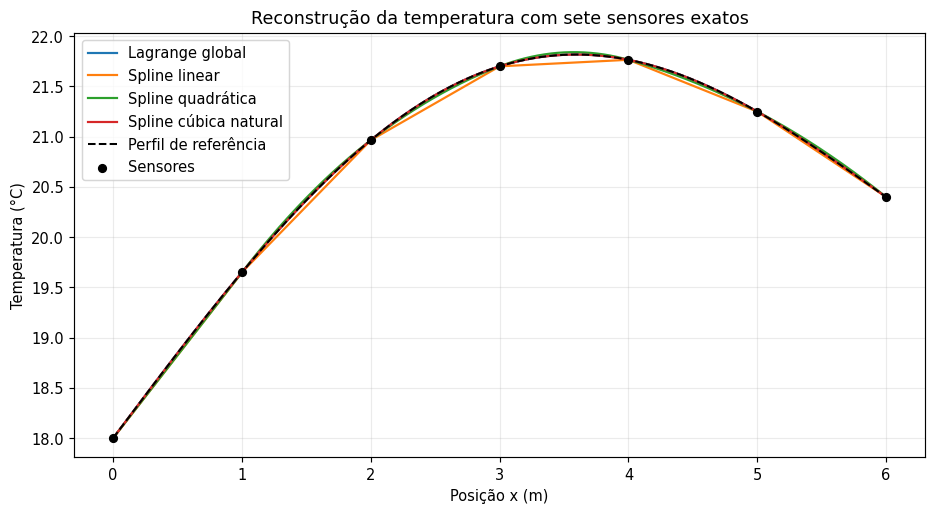

In [3]:
x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7.round(7))

fig, ax = plt.subplots()
for nome_metodo, metodo in metodos_7.items():
    ax.plot(x_fino, metodo(x_fino), label=nome_metodo)
ax.plot(x_fino, T_fino, "k--", linewidth=1.4, label="Perfil de referência")
ax.scatter(x_nos_7, y_nos_7, color="black", s=28, zorder=5, label="Sensores")
ax.set(xlabel="Posição x (m)", ylabel="Temperatura (°C)",
       title="Reconstrução da temperatura com sete sensores exatos")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

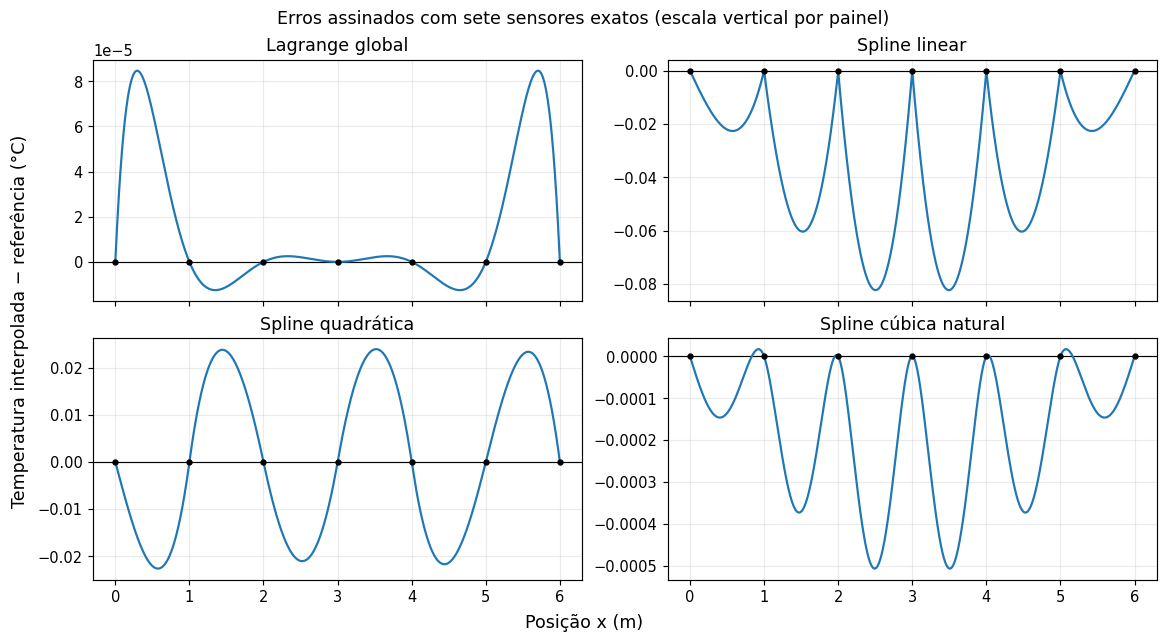

In [4]:
fig, eixos = plt.subplots(2, 2, figsize=(11, 6), sharex=True, layout="constrained")
for ax, (nome_metodo, metodo) in zip(eixos.flat, metodos_7.items()):
    erro = metodo(x_fino) - T_fino
    ax.axhline(0, color="black", linewidth=0.8)
    ax.plot(x_fino, erro, color="tab:blue")
    ax.scatter(x_nos_7, metodo(x_nos_7) - y_nos_7, color="black", s=11, zorder=3)
    ax.set_title(nome_metodo)
    ax.grid(alpha=0.25)
fig.suptitle("Erros assinados com sete sensores exatos (escala vertical por painel)")
fig.supxlabel("Posição x (m)")
fig.supylabel("Temperatura interpolada − referência (°C)")
plt.show()

## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

In [5]:
def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

linhas_nos = []
for N in (5, 9, 13, 17):
    distribuicoes = {
        "Equiespaçados": np.linspace(x_min, x_max, N),
        "Chebyshev–Lobatto": nos_chebyshev_lobatto(x_min, x_max, N),
    }
    for distribuicao, x_nos in distribuicoes.items():
        interpolador = BarycentricInterpolator(x_nos, temperatura_real(x_nos))
        erro = interpolador(x_fino) - T_fino
        linhas_nos.append({
            "Sensores": N,
            "Nós": distribuicao,
            "Erro máximo (°C)": np.max(np.abs(erro)),
            "RMSE (°C)": np.sqrt(np.mean(erro**2)),
        })

tabela_nos = pd.DataFrame(linhas_nos)
display(tabela_nos.assign(**{
    coluna: tabela_nos[coluna].map("{:.3e}".format)
    for coluna in ("Erro máximo (°C)", "RMSE (°C)")
}))

,Sensores,Nós,Erro máximo (°C),RMSE (°C)
0,5,Equiespaçados,4.530e-03,2.160e-03
1,5,Chebyshev–Lobatto,2.327e-03,1.533e-03
2,9,Equiespaçados,1.044e-06,3.438e-07
3,9,Chebyshev–Lobatto,2.168e-07,1.202e-07
4,13,Equiespaçados,5.922e-11,1.545e-11
5,13,Chebyshev–Lobatto,3.624e-12,1.932e-12
6,17,Equiespaçados,1.990e-12,2.445e-13
7,17,Chebyshev–Lobatto,1.421e-14,3.771e-15


Nas quatro quantidades testadas, os nós de Chebyshev–Lobatto reduziram o erro máximo e o RMSE de Lagrange. Com nove sensores, por exemplo, o erro máximo passou de aproximadamente $1{,}04\times10^{-6}$ °C para $2{,}17\times10^{-7}$ °C. A concentração de nós nas bordas reduz a sensibilidade da interpolação nessa região. O perfil de referência é a soma de uma reta com um seno suave, o que favorece a aproximação polinomial. Com 17 nós de Chebyshev–Lobatto, parte da diferença já está na escala do arredondamento numérico.

## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

,Sensores,Método,Erro máximo (°C),RMSE (°C),Construção (µs),Avaliação (µs)
0,4,Lagrange equiespaçado,1.090e-01,6.830e-02,37.3,107.0
1,4,Lagrange Chebyshev–Lobatto,1.430e-01,8.094e-02,35.8,106.3
2,4,Spline cúbica natural,1.018e-02,4.787e-03,93.4,21.2
3,5,Lagrange equiespaçado,4.530e-03,2.160e-03,39.5,113.4
4,5,Lagrange Chebyshev–Lobatto,2.327e-03,1.533e-03,36.3,113.7
...,...,...,...,...,...,...
106,39,Lagrange Chebyshev–Lobatto,1.776e-14,4.849e-15,157.9,388.6
107,39,Spline cúbica natural,3.043e-07,1.373e-07,91.6,22.1
108,40,Lagrange equiespaçado,1.142e-05,7.077e-07,170.6,402.4
109,40,Lagrange Chebyshev–Lobatto,1.776e-14,4.296e-15,160.4,374.7


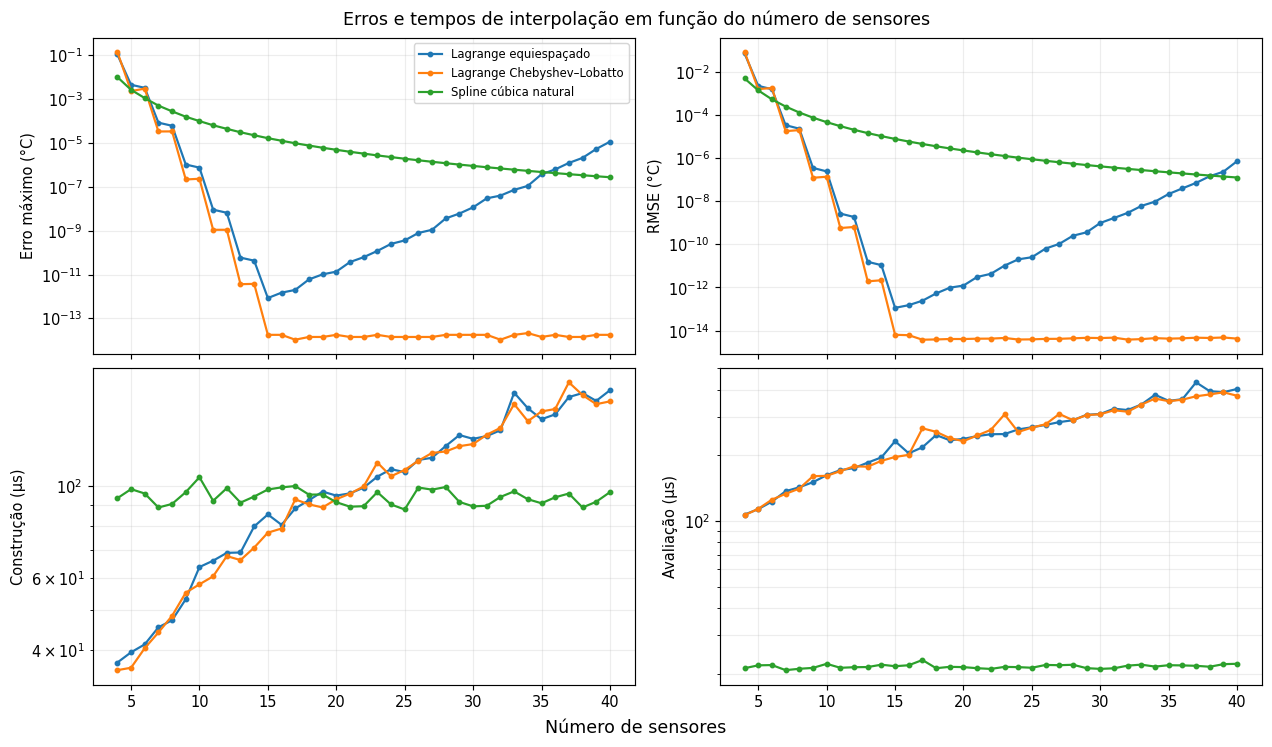

,Construção (µs),Avaliação (µs)
Método,,
Lagrange Chebyshev–Lobatto,99.8,261.5
Lagrange equiespaçado,99.1,249.7
Spline cúbica natural,94.1,21.5


In [6]:
from time import perf_counter_ns

N_MEDICOES = 9
linhas_varredura = []
for N in range(4, 41):
    x_uniforme = np.linspace(x_min, x_max, N)
    x_chebyshev = nos_chebyshev_lobatto(x_min, x_max, N)
    casos = {
        "Lagrange equiespaçado": (BarycentricInterpolator, x_uniforme),
        "Lagrange Chebyshev–Lobatto": (BarycentricInterpolator, x_chebyshev),
        "Spline cúbica natural": (lambda x, y: CubicSpline(x, y, bc_type="natural"),
                                  x_uniforme),
    }
    for nome_metodo, (construir, x_nos) in casos.items():
        y_nos = temperatura_real(x_nos)
        interpolador = construir(x_nos, y_nos)
        estimativa = interpolador(x_fino)
        tempos_construcao = []
        tempos_avaliacao = []
        for _ in range(N_MEDICOES):
            inicio = perf_counter_ns()
            interpolador = construir(x_nos, y_nos)
            construido = perf_counter_ns()
            interpolador(x_fino)
            avaliado = perf_counter_ns()
            tempos_construcao.append((construido - inicio) / 1_000)
            tempos_avaliacao.append((avaliado - construido) / 1_000)

        erro = estimativa - T_fino
        linhas_varredura.append({
            "Sensores": N,
            "Método": nome_metodo,
            "Erro máximo (°C)": np.max(np.abs(erro)),
            "RMSE (°C)": np.sqrt(np.mean(erro**2)),
            "Construção (µs)": np.median(tempos_construcao),
            "Avaliação (µs)": np.median(tempos_avaliacao),
        })

tabela_varredura = pd.DataFrame(linhas_varredura)
assert len(tabela_varredura) == 37 * 3
assert np.isfinite(tabela_varredura.select_dtypes("number")).all().all()

colunas = ["Erro máximo (°C)", "RMSE (°C)", "Construção (µs)", "Avaliação (µs)"]
formatos = {coluna: "{:.3e}" for coluna in colunas[:2]}
formatos.update({coluna: "{:.1f}" for coluna in colunas[2:]})
display(tabela_varredura.assign(**{
    coluna: tabela_varredura[coluna].map(formato.format)
    for coluna, formato in formatos.items()
}))

fig, eixos = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for ax, coluna in zip(eixos.flat, colunas):
    for nome_metodo, grupo in tabela_varredura.groupby("Método", sort=False):
        valores = grupo[coluna]
        if coluna in colunas[:2]:
            # Erro zero, se ocorrer, não tem representação em escala logarítmica.
            valores = valores.where(valores > 0)
        ax.plot(grupo["Sensores"], valores, marker=".", label=nome_metodo)
    ax.set_ylabel(coluna)
    ax.set_yscale("log")
    ax.grid(which="both", alpha=0.22)
eixos[0, 0].legend(fontsize=8)
fig.supxlabel("Número de sensores")
fig.suptitle("Erros e tempos de interpolação em função do número de sensores")
plt.show()

display(tabela_varredura.groupby("Método")[colunas[2:]].median().round(1))

### Interpretação da varredura

Com quatro sensores, a spline cúbica natural obteve o menor RMSE, cerca de $4{,}79\times10^{-3}$ °C. Com sete, Lagrange com Chebyshev–Lobatto obteve cerca de $1{,}73\times10^{-5}$ °C, o menor RMSE entre os três casos. O melhor método depende de $N$, da métrica e das hipóteses sobre as medições. Com cinco sensores, por exemplo, Chebyshev–Lobatto teve menor erro máximo e a cúbica natural teve menor RMSE.

A variante de Chebyshev–Lobatto chega perto de $10^{-14}$ °C de erro máximo, uma ordem compatível com o arredondamento em ponto flutuante das temperaturas usadas. Para Lagrange equiespaçado, o erro diminui inicialmente e volta a crescer para $N$ alto. Nesse trecho, a avaliação nas bordas fica sensível ao arredondamento, mesmo para este perfil suave. A cúbica natural apresentou queda mais regular nos erros e resolve polinômios de grau baixo em cada intervalo.

Os tempos são medianas de nove repetições para cada método e cada $N$. A construção exclui a geração dos nós e das temperaturas. A avaliação usa os mesmos 2.001 pontos para todos. Nesta execução, avaliar a spline cúbica foi mais rápido do que avaliar Lagrange. Na implementação baricêntrica usada, construir os pesos custa $O(N^2)$ e avaliar em $m$ pontos custa $O(mN)$. Na spline cúbica natural, a construção resolve um sistema tridiagonal em $O(N)$ e a avaliação usa apenas o polinômio do intervalo que contém cada ponto. Os tempos absolutos variam com a máquina.

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.

### Experimento com ruído de medição

Foram simuladas 100 realizações para cada quantidade de sensores (7 e 17), em nós equiespaçados. Em cada realização, os sensores internos receberam ruído gaussiano independente de média zero e desvio padrão de $0{,}10 ^circmathrm C$. As extremidades foram mantidas nos valores prescritos pelo modelo. Os quatro métodos receberam as mesmas leituras em cada realização.

As métricas foram calculadas contra o perfil analítico na malha fina. A tabela resume as medianas e o percentil 95 do erro máximo entre as realizações. O percentil 95 descreve estes cenários simulados sob o modelo de ruído adotado.

In [7]:
rng_ruido = np.random.default_rng(42)
desvio_ruido = 0.10  # °C
linhas_ruido = []
for N in (7, 17):
    x_nos = np.linspace(x_min, x_max, N)
    y_exato = temperatura_real(x_nos)
    for _ in range(100):
        y_medido = y_exato.copy()
        y_medido[1:-1] += rng_ruido.normal(0, desvio_ruido, size=N-2)
        metodos_ruido = criar_metodos(x_nos, y_medido)
        metricas = calcular_metricas(metodos_ruido, x_fino, T_fino)
        linhas_ruido.append(metricas.assign(Sensores=N))

tabela_ruido = pd.concat(linhas_ruido, ignore_index=True)
resumo_ruido = (
    tabela_ruido.groupby(["Sensores", "Método"])
    .agg(
        erro_max_mediano=("Erro máximo (°C)", "median"),
        erro_max_p95=("Erro máximo (°C)", lambda valores: valores.quantile(0.95)),
        mae_mediano=("MAE (°C)", "median"),
        rmse_mediano=("RMSE (°C)", "median"),
    )
    .sort_values(["Sensores", "rmse_mediano"])
    .rename(columns={
        "erro_max_mediano": "Erro máximo mediano (°C)",
        "erro_max_p95": "P95 do erro máximo (°C)",
        "mae_mediano": "MAE mediano (°C)",
        "rmse_mediano": "RMSE mediano (°C)",
    })
)
display(resumo_ruido.round(4))

Erro máximo mediano (°C)  P95 do erro máximo (°C)  MAE mediano (°C)  RMSE mediano (°C)
Sensores Método                                                                                                       
7        Spline cúbica natural                    0.1507                   0.2373            0.0640             0.0784
         Spline linear                            0.1711                   0.2574            0.0633             0.0801
         Lagrange global                          0.2144                   0.4057            0.0864             0.1045
         Spline quadrática                        0.2372                   0.3887            0.0866             0.1100
17       Spline linear                            0.2102                   0.2916            0.0620             0.0786
         Spline cúbica natural                    0.2182                   0.2968            0.0722             0.0903
         Spline quadrática                        0.4058                   0.8577            0.1308             0.1637
         Lagrange global                         23.8442                  75.4793            1.4027             4.3226

### Recomendação técnica

1. **Com poucos sensores exatos, a escolha depende de quantos estão disponíveis.** Com sete sensores equiespaçados, escolheria Lagrange para este perfil suave. O erro máximo foi cerca de $8{,}47\times10^{-5}$ °C e o RMSE foi $3{,}27\times10^{-5}$ °C. Para a cúbica natural, foram $5{,}06\times10^{-4}$ °C e $2{,}39\times10^{-4}$ °C. Com quatro sensores, a cúbica natural teve menor erro máximo e RMSE que as duas variantes de Lagrange.
2. **Com mais sensores exatos, levaria em conta a liberdade de posicionamento.** Se for possível instalar os sensores nas posições de Chebyshev–Lobatto, usaria Lagrange nesses nós para um perfil suave como o da atividade. Se os sensores já forem equiespaçados e numerosos, preferiria a spline cúbica natural pela estabilidade e pelo menor tempo de avaliação medido na varredura.
3. **Com ruído, começaria pela spline linear como referência e testaria suavização.** Todos os quatro interpoladores passam pelos valores medidos nos nós e, portanto, incorporam o ruído. Com sete sensores ruidosos, a cúbica natural teve RMSE mediano de $0{,}0784$ °C e erro máximo mediano de $0{,}1507$ °C. Com 17, a linear obteve $0{,}0786$ °C e $0{,}2102$ °C nessas métricas, enquanto Lagrange equiespaçado chegou a $4{,}3226$ °C e $23{,}8442$ °C. Para obter uma curva suave, testaria uma spline de suavização e ajustaria sua intensidade por validação com sensores internos reservados. Os resultados da tabela são dos interpoladores avaliados.
4. **Nas extremidades, manteria os valores de contorno quando eles forem conhecidos.** Usaria sensores próximos às bordas, verificaria os erros por região e observaria picos entre o primeiro e o segundo sensor e entre os dois últimos. A condição de segunda derivada nula da spline natural é coerente com este perfil analítico nas duas pontas. Em campo, avaliaria essa hipótese com base nas condições físicas. Dentro do intervalo medido, a estimativa é interpolação. Além do primeiro ou do último sensor, passa a ser extrapolação e exigiria um modelo físico validado ou novas medições.
5. **Em campo, estimaria a qualidade com dados reservados e medições repetidas.** Usaria leituras de sensores internos fora do ajuste, manteria os sensores de contorno e calcularia RMSE e erro máximo nesses pontos. Medições repetidas ajudariam a estimar o ruído e a calibração ajudaria a identificar vieses. A validação mede desvios em relação às leituras reservadas e não revela diretamente o erro contra a temperatura verdadeira entre sensores. O percentil 95 da simulação depende do modelo de ruído adotado e não é um limite de erro de campo.